Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf

print("Everything is ready!")
print("TensorFlow version:", tf.__version__)

Everything is ready!
TensorFlow version: 2.21.0


1. Loading the Dataset

In [2]:
import pandas as pd

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)

train.head()

Training data shape: (42000, 785)
Test data shape: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Exploring the Dataset - Inspecting the column names to understand how the labels and image pixels are stored.

In [3]:
print(train.columns)

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='str', length=785)


Understanding Pixel Values - Checking the range of image pixel values.

In [4]:
pixels = train.drop("label", axis=1)

print("Minimum pixel value:", pixels.min().min())
print("Maximum pixel value:", pixels.max().max())

Minimum pixel value: 0
Maximum pixel value: 255


Visualizing a Digit - Displaying the first handwritten image.

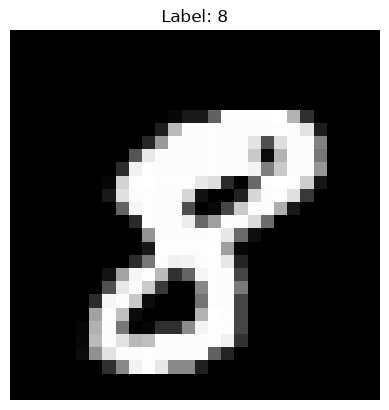

In [7]:
image = pixels.iloc[10].to_numpy().reshape(28, 28)

plt.imshow(image, cmap="gray")
plt.title(f"Label: {train.iloc[10]['label']}")
plt.axis("off")
plt.show()

Separating Features and Labels - Preparing the data for model training.

In [8]:
X = train.drop("label", axis=1)
y = train["label"]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (42000, 784)
Labels shape: (42000,)


Normalizing Pixel Values - Scaling pixel values to improve model training.

In [9]:
X = X / 255.0

print("Minimum pixel value:", X.min().min())
print("Maximum pixel value:", X.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


Splitting the Dataset - Creating training and validation sets to evaluate the model.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples: 33600
Validation samples: 8400


Logistic Regression - Training a simple baseline model for digit classification.

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Evaluating Logistic Regression - Measuring the model's accuracy on validation data.

In [12]:
from sklearn.metrics import accuracy_score

y_val_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_val_pred)

print("Validation Accuracy:", accuracy)
print("Validation Accuracy (%):", accuracy * 100)

Validation Accuracy: 0.9130952380952381
Validation Accuracy (%): 91.30952380952381


Baseline Result - Logistic Regression achieved 91.31% validation accuracy.

Reshaping Images - Converting pixel arrays into 28 × 28 image grids for the CNN.

In [13]:
X_train_cnn = X_train.to_numpy().reshape(-1, 28, 28, 1)
X_val_cnn = X_val.to_numpy().reshape(-1, 28, 28, 1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN validation shape:", X_val_cnn.shape)

CNN training shape: (33600, 28, 28, 1)
CNN validation shape: (8400, 28, 28, 1)


Building the CNN - Defining layers to learn visual patterns from handwritten digits.

In [14]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

cnn_model = Sequential([
    Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

cnn_model.summary()

c:\Users\DELL\OneDrive\Documents\Desktop\vcs - digit recognizer\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Compiling the CNN - Configuring the optimizer, loss function, and evaluation metric.

In [15]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Training the CNN - Learning digit patterns from the training images.

In [16]:
history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val_cnn, y_val)
)

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9239 - loss: 0.2498 - val_accuracy: 0.9742 - val_loss: 0.0777
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9763 - loss: 0.0759 - val_accuracy: 0.9810 - val_loss: 0.0608
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9828 - loss: 0.0547 - val_accuracy: 0.9850 - val_loss: 0.0479
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9872 - loss: 0.0421 - val_accuracy: 0.9849 - val_loss: 0.0490
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9890 - loss: 0.0340 - val_accuracy: 0.9857 - val_loss: 0.0480
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9909 - loss: 0.0290 - val_accuracy: 0.9882 - val_loss: 0.0425
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9929 - loss: 0.0234 - val_accuracy: 0.9881 - val_loss: 0.0442
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9929 - loss: 0.0218 - val_accu

CNN Training Result - The model achieved 98.88% validation accuracy after 10 epochs.

Model Comparison - Comparing Logistic Regression and CNN validation accuracy.

In [17]:
from sklearn.metrics import accuracy_score

# Logistic Regression accuracy
lr_accuracy = accuracy_score(y_val, y_val_pred)

# CNN predictions
y_cnn_pred = cnn_model.predict(X_val_cnn).argmax(axis=1)

# CNN accuracy
cnn_accuracy = accuracy_score(y_val, y_cnn_pred)

print(f"Logistic Regression: {lr_accuracy * 100:.2f}%")
print(f"CNN: {cnn_accuracy * 100:.2f}%")

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Logistic Regression: 91.31%
CNN: 98.88%


Preparing Test Data - Normalizing and reshaping images for CNN predictions.

In [18]:
X_test = test / 255.0

X_test_cnn = X_test.to_numpy().reshape(-1, 28, 28, 1)

print("Test data shape:", X_test_cnn.shape)

Test data shape: (28000, 28, 28, 1)


Generating Predictions - Predicting handwritten digits in the Kaggle test dataset.

In [19]:
test_probabilities = cnn_model.predict(X_test_cnn)

test_predictions = test_probabilities.argmax(axis=1)

print("Number of predictions:", len(test_predictions))
print("First 10 predictions:", test_predictions[:10])

875/875 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
Number of predictions: 28000
First 10 predictions: [2 0 9 9 3 7 0 3 0 3]


Creating Submission - Formatting predictions for the Kaggle competition.

In [20]:
submission = pd.DataFrame({
    "ImageId": range(1, len(test_predictions) + 1),
    "Label": test_predictions
})

submission.to_csv("submission.csv", index=False)

submission.head()

,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3


Checking Submission - Verifying the file format before uploading to Kaggle.

In [21]:
print("Submission shape:", submission.shape)
print("Column names:", submission.columns.tolist())
print("Missing values:", submission.isnull().sum().sum())

Submission shape: (28000, 2)
Column names: ['ImageId', 'Label']
Missing values: 0


Experiment Results - Comparing the validation performance of our models.

In [22]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "CNN"],
    "Validation Accuracy": [lr_accuracy, cnn_accuracy]
})

results

,Model,Validation Accuracy
0,Logistic Regression,0.913095
1,CNN,0.988810


Saving Results - Exporting model comparison results for project documentation.

In [23]:
results.to_csv("model_results.csv", index=False)

Saving the CNN - Storing the trained model for future use.

In [24]:
cnn_model.save("digit_recognizer_cnn.keras")

In [25]:
import os

print("Model saved:", os.path.exists("digit_recognizer_cnn.keras"))

Model saved: True


Prediction Visualization - Displaying a test image and its predicted digit.

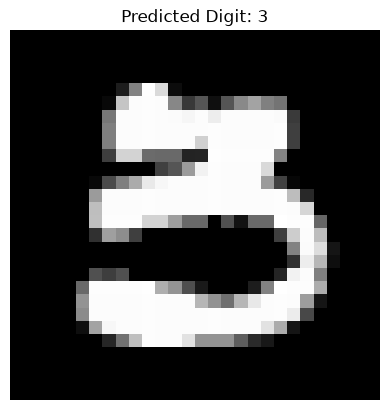

In [27]:
import matplotlib.pyplot as plt

index = 15

plt.imshow(X_test_cnn[index].reshape(28, 28), cmap="gray")
plt.title(f"Predicted Digit: {test_predictions[index]}")
plt.axis("off")
plt.show()